<a href="https://colab.research.google.com/github/melaniee-sudo/machine-learning-udg-tareas/blob/main/p12_kmeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Resultados para k = 1
Silhouette: No definido
Davies-Bouldin: No definido

Resultados para k = 2
Silhouette Score: 0.2593
Davies-Bouldin Score: 1.5260

Resultados para k = 3
Silhouette Score: 0.2849
Davies-Bouldin Score: 1.3892

Resultados para k = 4
Silhouette Score: 0.2602
Davies-Bouldin Score: 1.7969

Resultados para k = 5
Silhouette Score: 0.2016
Davies-Bouldin Score: 1.8083

Mejor k según Silhouette: 3
Mejor k según Davies-Bouldin: 3


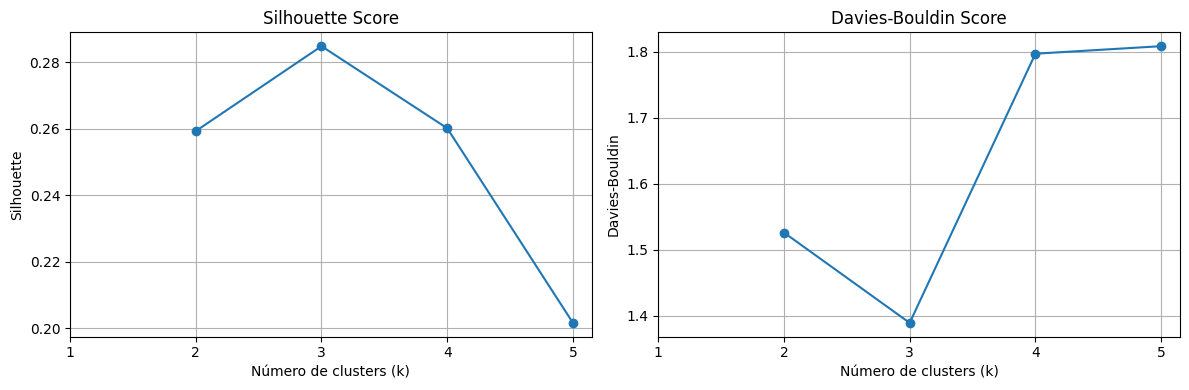

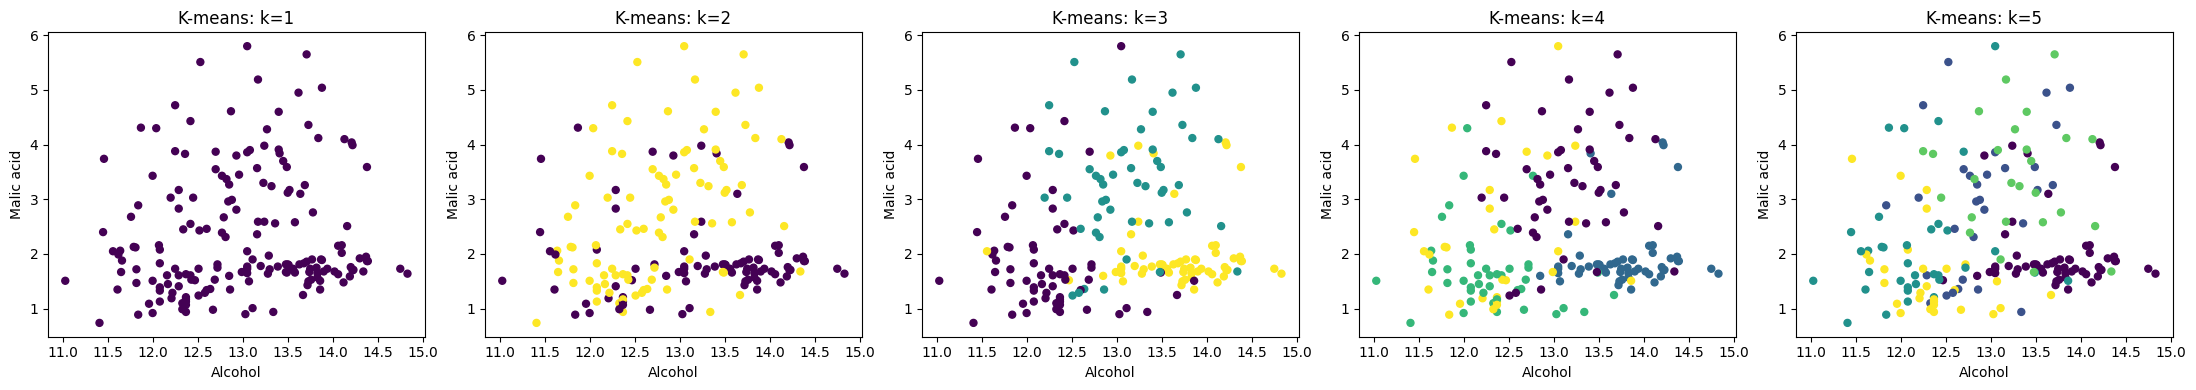

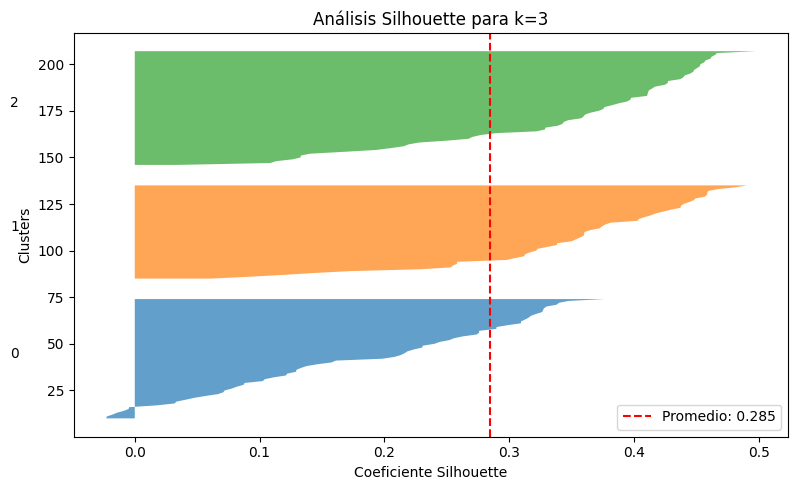

In [1]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score
)

#base de datos wine
wine = load_wine()
X_original = wine.data

#normalizar todas las caracteristicas
scaler = StandardScaler()
X = scaler.fit_transform(X_original)

k_values = range(1, 6)

silhouette_scores = []
davies_bouldin_scores = []

etiquetas_por_k = {}
kmeans_por_k = {}

mejor_k_sil = None
mejor_silhouette = -1

mejor_k_db = None
mejor_davies = float("inf")

#entrenar K-means para k = 1, 2, 3, 4, 5
for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = kmeans.fit_predict(X)

    kmeans_por_k[k] = kmeans
    etiquetas_por_k[k] = etiquetas

    print(f"\nResultados para k = {k}")

    if k == 1:
        silhouette_scores.append(np.nan)
        davies_bouldin_scores.append(np.nan)

        print("Silhouette: No definido")
        print("Davies-Bouldin: No definido")
        continue

    #calcular las metricas
    score_sil = silhouette_score(X, etiquetas)
    score_db = davies_bouldin_score(X, etiquetas)

    silhouette_scores.append(score_sil)
    davies_bouldin_scores.append(score_db)

    print(f"Silhouette Score: {score_sil:.4f}")
    print(f"Davies-Bouldin Score: {score_db:.4f}")

    #identificar mejor k segun Silhouette
    if score_sil > mejor_silhouette:
        mejor_silhouette = score_sil
        mejor_k_sil = k

    #identificar mejor k segun Davies-Bouldin
    if score_db < mejor_davies:
        mejor_davies = score_db
        mejor_k_db = k

print("\nMejor k según Silhouette:", mejor_k_sil)
print("Mejor k según Davies-Bouldin:", mejor_k_db)

#graficar resultados de las metricas
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(k_values, silhouette_scores, marker="o")
ax1.set_title("Silhouette Score")
ax1.set_xlabel("Número de clusters (k)")
ax1.set_ylabel("Silhouette")
ax1.set_xticks(list(k_values))
ax1.grid(True)

ax2.plot(k_values, davies_bouldin_scores, marker="o")
ax2.set_title("Davies-Bouldin Score")
ax2.set_xlabel("Número de clusters (k)")
ax2.set_ylabel("Davies-Bouldin")
ax2.set_xticks(list(k_values))
ax2.grid(True)

plt.tight_layout()
plt.show()

#visualizar agrupamientos para todos los k
fig, ejes = plt.subplots(1, 5, figsize=(22, 4))

for k in k_values:
    etiquetas = etiquetas_por_k[k]

    ejes[k-1].scatter(
        X_original[:, 0],
        X_original[:, 1],
        c=etiquetas,
        cmap="viridis",
        s=25
    )

    ejes[k-1].set_title(f"K-means: k={k}")
    ejes[k-1].set_xlabel("Alcohol")
    ejes[k-1].set_ylabel("Malic acid")

plt.tight_layout()
plt.show()

#grafica de Silhouette para el mejor k
etiquetas_mejor = etiquetas_por_k[mejor_k_sil]
valores_sil = silhouette_samples(X, etiquetas_mejor)

fig, ax = plt.subplots(figsize=(8, 5))
y_lower = 10

for i in range(mejor_k_sil):
    valores_cluster = valores_sil[etiquetas_mejor == i]
    valores_cluster.sort()

    cantidad = len(valores_cluster)
    y_upper = y_lower + cantidad

    ax.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        valores_cluster,
        alpha=0.7
    )

    ax.text(-0.1, y_lower + cantidad / 2, str(i))
    y_lower = y_upper + 10

ax.axvline(
    mejor_silhouette,
    color="red",
    linestyle="--",
    label=f"Promedio: {mejor_silhouette:.3f}"
)

ax.set_title(f"Análisis Silhouette para k={mejor_k_sil}")
ax.set_xlabel("Coeficiente Silhouette")
ax.set_ylabel("Clusters")
ax.legend()

plt.tight_layout()
plt.show()
